**Blinkit Sales & Outlet Performance Analysis**

Standalone Python Data Analytics Project

Tools: Python, Pandas, NumPy, Matplotlib, Seaborn
Environment: Google Colab
Dataset: blinkit_data.csv (8,523 rows × 12 columns)

**1. Project overview**

This project analyzes Blinkit grocery-item sales, product characteristics, outlet performance, outlet location and customer ratings. The objective is to turn the supplied dataset into clear, evidence-based business insights using Python only.

**Business questions**
- What are the overall sales, average sales, item-record count and average rating?
- Which item types and fat-content groups contribute the most sales?
- How do sales vary by outlet, outlet type, outlet size and location tier?
- How do outlet establishment years compare?
- What relationships appear among numerical variables?
- What practical recommendations are supported by the analysis?

**Important metric definitions**
- Total Sales: sum of the Sales column.
- Average Sales: mean of Sales per dataset row (not average order value; the file has no order ID).
- Number of Items: number of item records/rows. We will also calculate distinct item identifiers separately.
- Average Rating: mean of Rating.
- The dataset does not contain cost, profit, order date, customer ID or geographic coordinates. Therefore, this project will not claim profit, customer-level behavior, time trends or plot an actual geographic map

**2 Import libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

**3.Load the dataset**

In [2]:
from google.colab import files
uploaded = files.upload()

# Use the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Saving blinkit_data.csv to blinkit_data.csv
Dataset loaded successfully.
Shape: (8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.10,15.10,145.48,5.00
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.01,11.80,115.35,5.00
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.03,13.85,165.02,5.00
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.04,12.15,126.50,5.00
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.03,19.60,55.16,5.00


**4.Understand the dataset**

In [3]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nNumerical summary:")
display(df.describe())

print("\nCategorical summary:")
display(df.describe(include="object"))

Rows and columns: (8523, 12)

Column names:
['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Item Weight', 'Sales', 'Rating']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null 

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,"8,523.00","8,523.00","7,060.00","8,523.00","8,523.00"
mean,"2,010.83",0.07,12.86,140.99,3.97
std,8.37,0.05,4.64,62.28,0.61
min,"1,998.00",0.00,4.55,31.29,1.00
25%,"2,000.00",0.03,8.77,93.83,4.00
50%,"2,012.00",0.05,12.60,143.01,4.00
75%,"2,017.00",0.09,16.85,185.64,4.20
max,"2,022.00",0.33,21.35,266.89,5.00



Categorical summary:


,Item Fat Content,Item Identifier,Item Type,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type
count,8523,8523,8523,8523,8523,8523,8523
unique,5,1559,16,10,3,3,4
top,Low Fat,FDW13,Fruits and Vegetables,OUT027,Tier 3,Medium,Supermarket Type1
freq,5089,10,1232,935,3350,3631,5577


**5. Data quality checks**

In [4]:
print("Missing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate rows:", df.duplicated().sum())

print("Unique item identifiers:", df["Item Identifier"].nunique())
print("Unique outlets:", df["Outlet Identifier"].nunique())

Missing values by column:


,Missing Values
Item Fat Content,0
Item Identifier,0
Item Type,0
Outlet Establishment Year,0
Outlet Identifier,0
Outlet Location Type,0
Outlet Size,0
Outlet Type,0
Item Visibility,0
Item Weight,1463


Duplicate rows: 0
Unique item identifiers: 1559
Unique outlets: 10


**6.Data cleaning**

In [5]:
# Keep an untouched copy for reference
raw_df = df.copy()

# Standardize category labels
df["Item Fat Content"] = df["Item Fat Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
})

# Fill missing item weights with the median
missing_weight_before = df["Item Weight"].isna().sum()
weight_median = df["Item Weight"].median()
df["Item Weight"] = df["Item Weight"].fillna(weight_median)

print("Missing Item Weight values before cleaning:", missing_weight_before)
print("Median used:", round(weight_median, 2))
print("Missing values after cleaning:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nStandardized fat-content categories:")
print(df["Item Fat Content"].value_counts())

Missing Item Weight values before cleaning: 1463
Median used: 12.6
Missing values after cleaning: 0
Duplicate rows: 0

Standardized fat-content categories:
Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


**7.Feature prepartion**

In [6]:
# Convert establishment year to a categorical field for grouped comparisons
df["Outlet Establishment Year"] = df["Outlet Establishment Year"].astype(int)

# Add an establishment-age grouping label for descriptive analysis.
# This is based on the years present in the dataset, not the current calendar year.
df["Outlet Establishment Year"] = df["Outlet Establishment Year"].astype("int64")

display(df.head())

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.10,15.10,145.48,5.00
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.01,11.80,115.35,5.00
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.03,13.85,165.02,5.00
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.04,12.15,126.50,5.00
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.03,19.60,55.16,5.00


**8.Key performance indicators**

In [7]:
total_sales = df["Sales"].sum()
average_sales = df["Sales"].mean()
number_of_item_records = len(df)
unique_items = df["Item Identifier"].nunique()
average_rating = df["Rating"].mean()

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Average Sales per Record",
        "Number of Item Records",
        "Unique Item Identifiers",
        "Average Rating"
    ],
    "Value": [
        total_sales,
        average_sales,
        number_of_item_records,
        unique_items,
        average_rating
    ]
})

display(kpi_summary)
print(f"Total Sales: {total_sales:,.2f}")
print(f"Average Sales per record: {average_sales:,.2f}")
print(f"Item records: {number_of_item_records:,}")
print(f"Unique item identifiers: {unique_items:,}")
print(f"Average rating: {average_rating:.2f} / 5")

,KPI,Value
0,Total Sales,"1,201,681.48"
1,Average Sales per Record,140.99
2,Number of Item Records,"8,523.00"
3,Unique Item Identifiers,"1,559.00"
4,Average Rating,3.97


Total Sales: 1,201,681.48
Average Sales per record: 140.99
Item records: 8,523
Unique item identifiers: 1,559
Average rating: 3.97 / 5


**9.Univariate analysis**

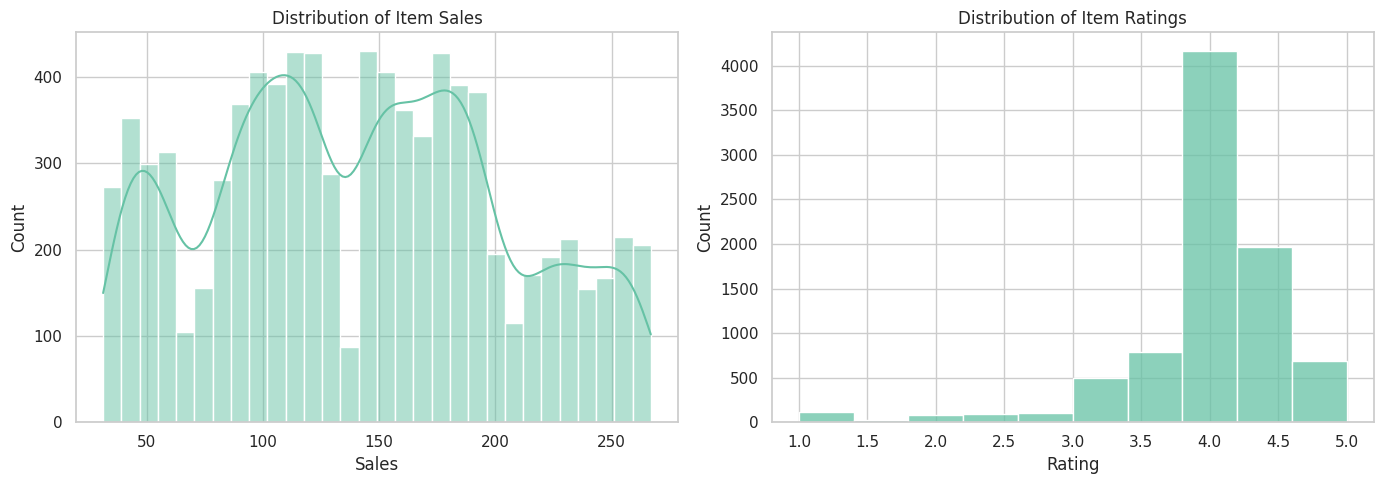

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Sales"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Item Sales")
axes[0].set_xlabel("Sales")

sns.histplot(df["Rating"], bins=10, kde=False, ax=axes[1])
axes[1].set_title("Distribution of Item Ratings")
axes[1].set_xlabel("Rating")

plt.tight_layout()
plt.show()

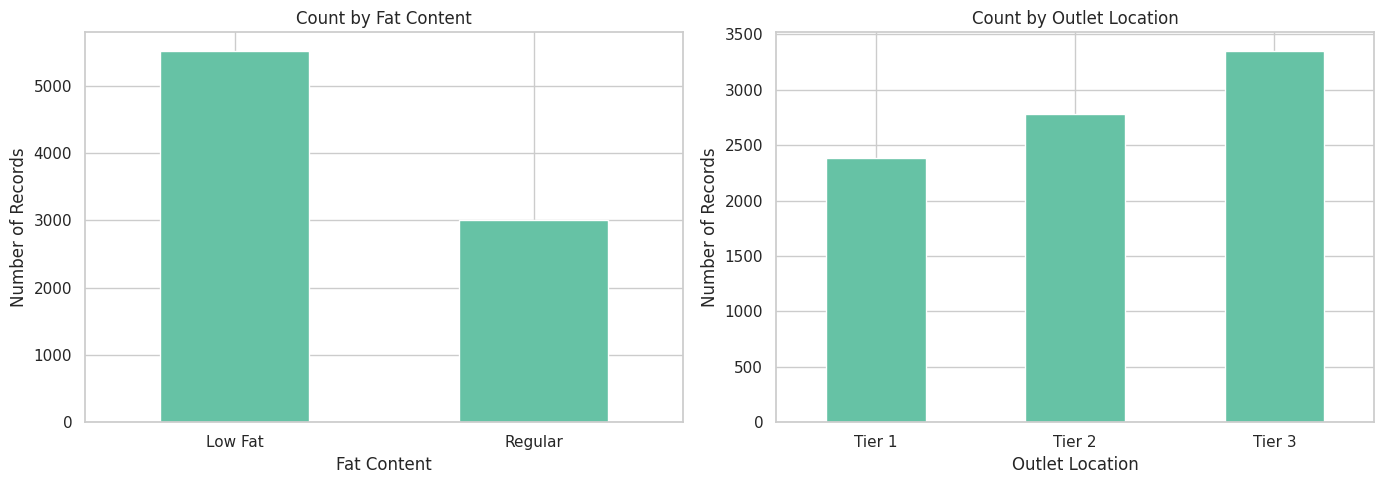

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["Item Fat Content"].value_counts().plot(
    kind="bar", ax=axes[0], title="Count by Fat Content"
)
axes[0].set_xlabel("Fat Content")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=0)

df["Outlet Location Type"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="Count by Outlet Location"
)
axes[1].set_xlabel("Outlet Location")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**10.sales analysis by fat content(donut chart)**

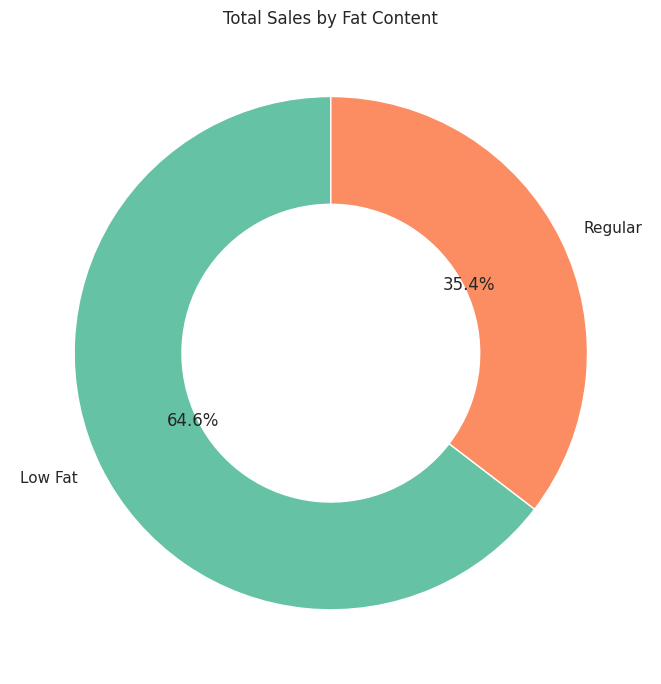

,Total Sales
Item Fat Content,
Low Fat,"776,319.68"
Regular,"425,361.80"


In [10]:
fat_sales = df.groupby("Item Fat Content")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(7, 7))
plt.pie(
    fat_sales,
    labels=fat_sales.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42, "edgecolor": "white"}
)
plt.title("Total Sales by Fat Content")
plt.tight_layout()
plt.show()

display(fat_sales.to_frame("Total Sales"))

**11. Sales by item type (Horizontal bar chart)**

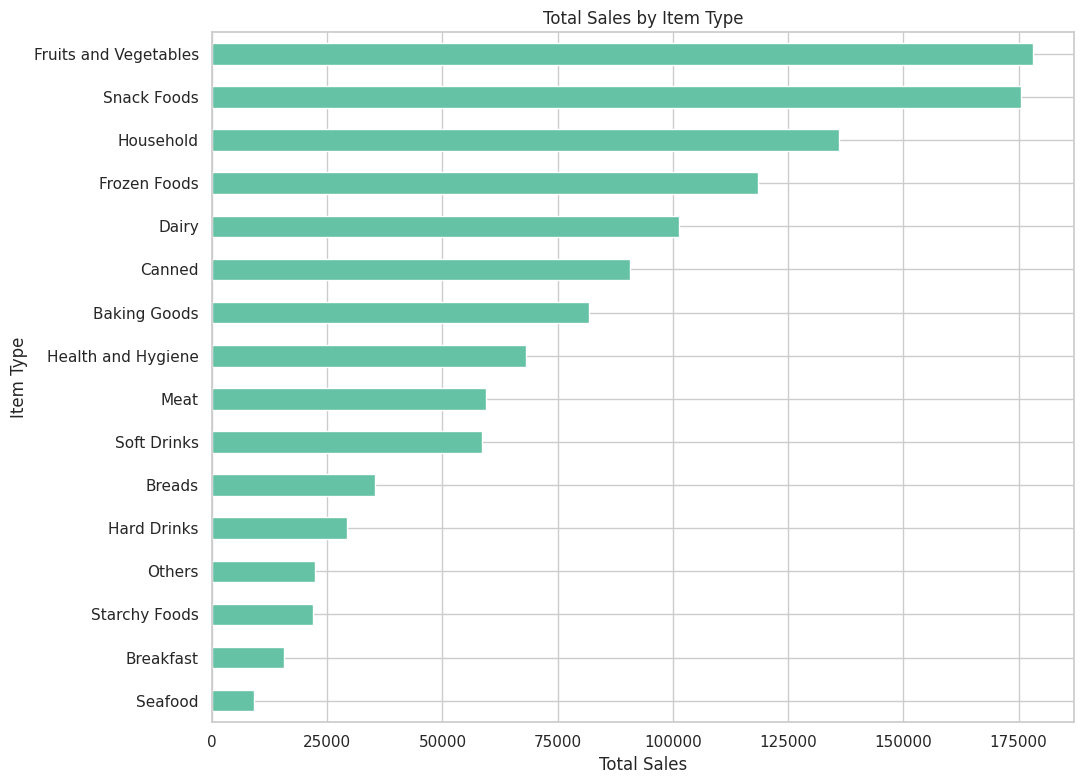

,Total Sales
Item Type,
Fruits and Vegetables,"178,124.08"
Snack Foods,"175,433.92"
Household,"135,976.53"
Frozen Foods,"118,558.88"
Dairy,"101,276.46"
Canned,"90,706.73"
Baking Goods,"81,894.74"
Health and Hygiene,"68,025.84"
Meat,"59,449.86"


In [11]:
item_sales = df.groupby("Item Type")["Sales"].sum().sort_values(ascending=True)

plt.figure(figsize=(11, 8))
item_sales.plot(kind="barh")
plt.title("Total Sales by Item Type")
plt.xlabel("Total Sales")
plt.ylabel("Item Type")
plt.tight_layout()
plt.show()

display(item_sales.sort_values(ascending=False).to_frame("Total Sales"))

**12. Fat content by outlet (Stacked column chart)**

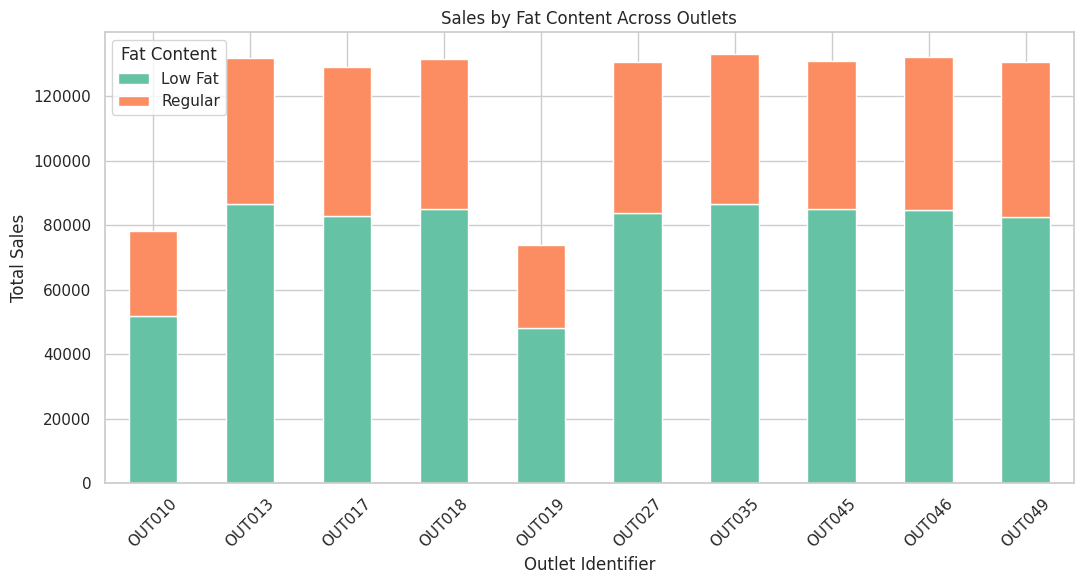

Item Fat Content,Low Fat,Regular
Outlet Identifier,,
OUT010,"51,785.83","26,345.74"
OUT013,"86,402.14","45,406.87"
OUT017,"82,947.05","46,156.91"
OUT018,"84,844.61","46,633.17"
OUT019,"48,028.54","25,779.05"
OUT027,"83,774.41","46,940.26"
OUT035,"86,482.92","46,620.99"
OUT045,"85,034.81","45,907.97"
OUT046,"84,603.32","47,510.05"


In [12]:
outlet_fat_sales = pd.pivot_table(
    df,
    index="Outlet Identifier",
    columns="Item Fat Content",
    values="Sales",
    aggfunc="sum",
    fill_value=0
)

outlet_fat_sales.plot(kind="bar", stacked=True, figsize=(11, 6))
plt.title("Sales by Fat Content Across Outlets")
plt.xlabel("Outlet Identifier")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.legend(title="Fat Content")
plt.tight_layout()
plt.show()

display(outlet_fat_sales)

**13. Sales by outlet establishment year (Line chart)**

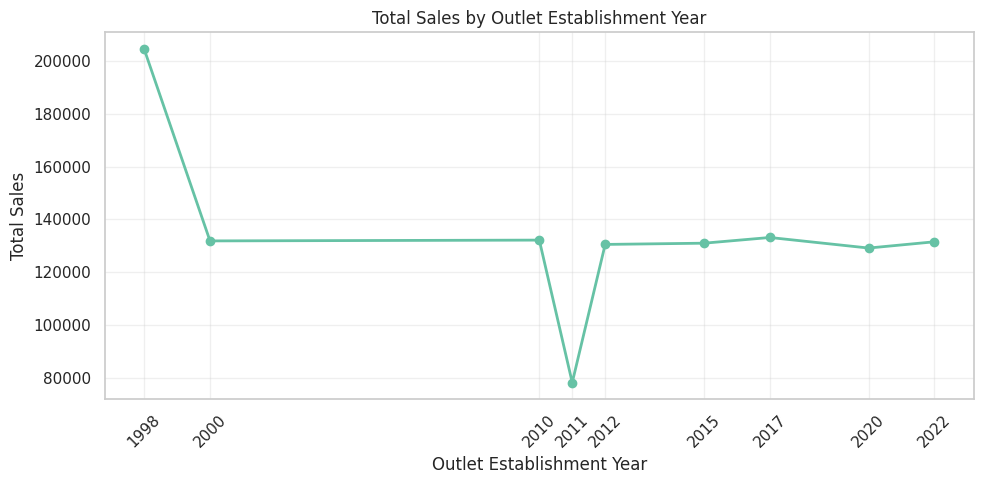

,Total Sales
Outlet Establishment Year,
1998,"204,522.26"
2000,"131,809.02"
2010,"132,113.37"
2011,"78,131.56"
2012,"130,476.86"
2015,"130,942.78"
2017,"133,103.91"
2020,"129,103.96"
2022,"131,477.77"


In [13]:
year_sales = df.groupby("Outlet Establishment Year")["Sales"].sum().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(year_sales.index, year_sales.values, marker="o", linewidth=2)
plt.title("Total Sales by Outlet Establishment Year")
plt.xlabel("Outlet Establishment Year")
plt.ylabel("Total Sales")
plt.xticks(year_sales.index, rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(year_sales.to_frame("Total Sales"))

**14. Sales by outlet size (Pie chart)**

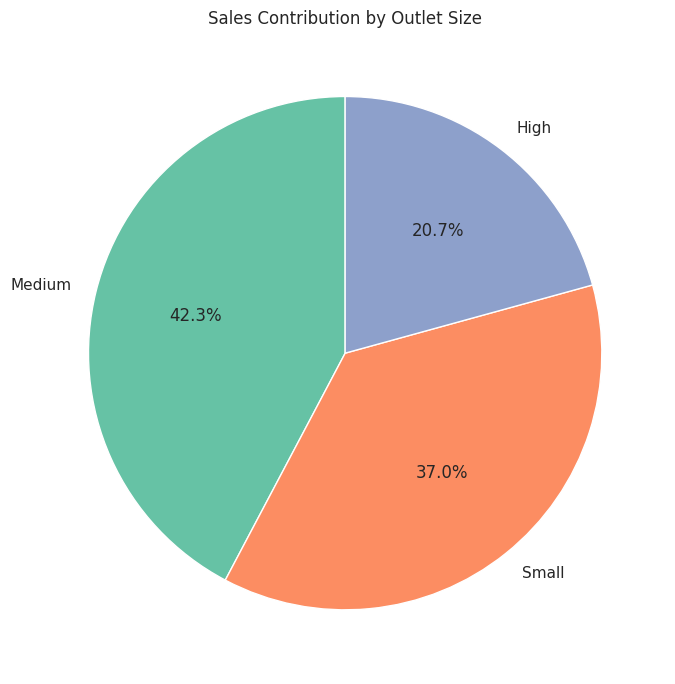

,Total Sales
Outlet Size,
Medium,"507,895.73"
Small,"444,794.17"
High,"248,991.58"


In [14]:
size_sales = df.groupby("Outlet Size")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(7, 7))
plt.pie(
    size_sales,
    labels=size_sales.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Sales Contribution by Outlet Size")
plt.tight_layout()
plt.show()

display(size_sales.to_frame("Total Sales"))

**15. Sales by outlet location (Bar chart)**

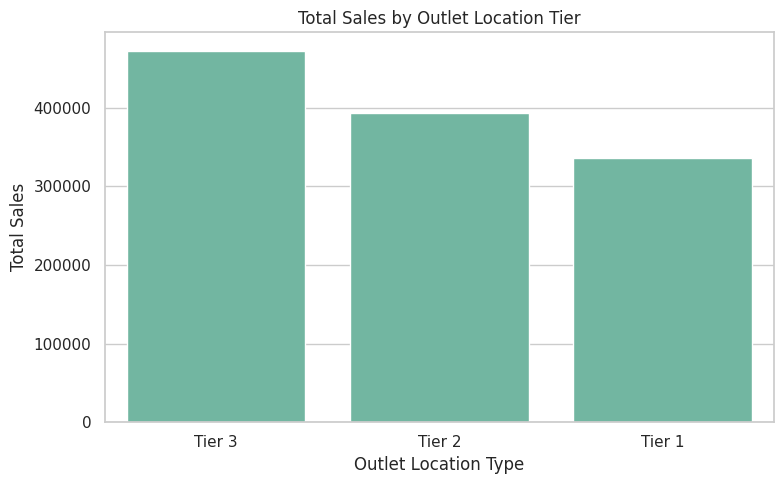

,Total Sales
Outlet Location Type,
Tier 3,"472,133.03"
Tier 2,"393,150.64"
Tier 1,"336,397.81"


In [15]:
location_sales = df.groupby("Outlet Location Type")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=location_sales.index, y=location_sales.values)
plt.title("Total Sales by Outlet Location Tier")
plt.xlabel("Outlet Location Type")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

display(location_sales.to_frame("Total Sales"))

**16. Outlet performance comparison**

In [16]:
outlet_summary = df.groupby("Outlet Type").agg(
    Total_Sales=("Sales", "sum"),
    Average_Sales=("Sales", "mean"),
    Item_Records=("Item Identifier", "count"),
    Average_Rating=("Rating", "mean"),
    Average_Item_Visibility=("Item Visibility", "mean")
).sort_values("Total_Sales", ascending=False)

display(outlet_summary)

,Total_Sales,Average_Sales,Item_Records,Average_Rating,Average_Item_Visibility
Outlet Type,,,,,
Supermarket Type1,"787,549.89",141.21,5577,3.96,0.06
Grocery Store,"151,939.15",140.29,1083,3.99,0.10
Supermarket Type2,"131,477.77",141.68,928,3.97,0.06
Supermarket Type3,"130,714.67",139.80,935,3.95,0.06


**17. Item performance and rating analysis**

In [17]:
item_summary = df.groupby("Item Type").agg(
    Total_Sales=("Sales", "sum"),
    Average_Sales=("Sales", "mean"),
    Item_Records=("Item Identifier", "count"),
    Average_Rating=("Rating", "mean")
).sort_values("Total_Sales", ascending=False)

display(item_summary)

,Total_Sales,Average_Sales,Item_Records,Average_Rating
Item Type,,,,
Fruits and Vegetables,"178,124.08",144.58,1232,3.96
Snack Foods,"175,433.92",146.19,1200,3.95
Household,"135,976.53",149.42,910,4.00
Frozen Foods,"118,558.88",138.50,856,3.97
Dairy,"101,276.46",148.50,682,3.97
Canned,"90,706.73",139.76,649,3.99
Baking Goods,"81,894.74",126.38,648,3.98
Health and Hygiene,"68,025.84",130.82,520,3.99
Meat,"59,449.86",139.88,425,4.02


In [18]:
rating_by_outlet = df.groupby("Outlet Identifier").agg(
    Average_Rating=("Rating", "mean"),
    Total_Sales=("Sales", "sum"),
    Item_Records=("Rating", "count")
).sort_values("Average_Rating", ascending=False)

display(rating_by_outlet)

,Average_Rating,Total_Sales,Item_Records
Outlet Identifier,,,
OUT019,4.00,"73,807.58",528
OUT049,3.99,"130,476.86",930
OUT017,3.98,"129,103.96",926
OUT010,3.98,"78,131.56",555
OUT018,3.97,"131,477.77",928
OUT045,3.96,"130,942.78",929
OUT046,3.96,"132,113.37",930
OUT027,3.95,"130,714.67",935
OUT013,3.95,"131,809.02",932


**18. Bivariate analysis**

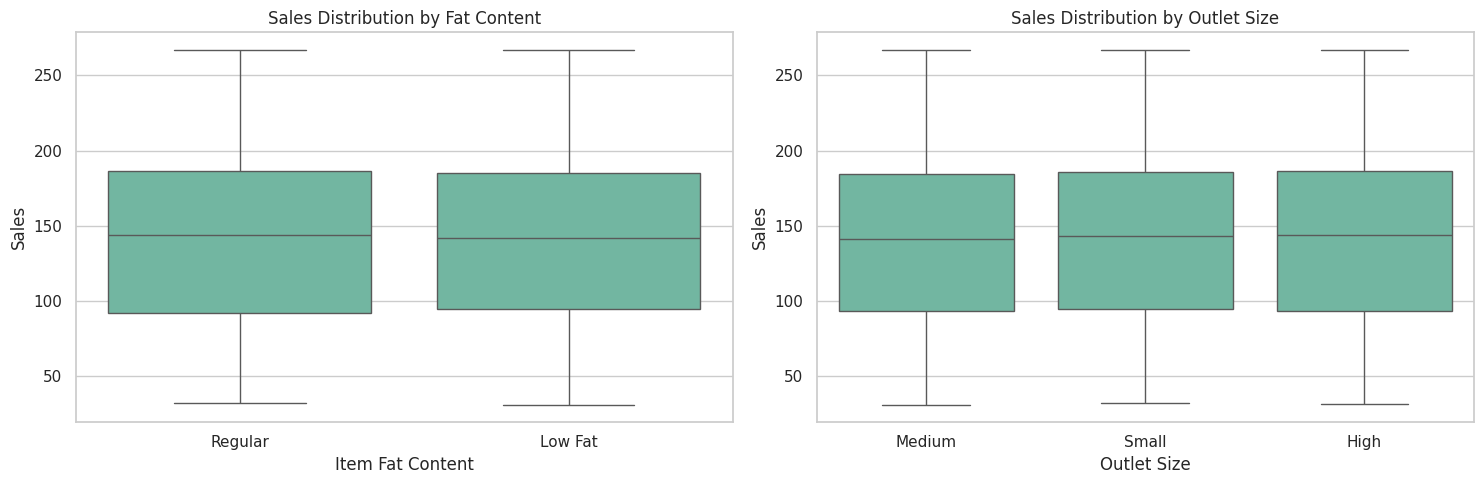

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df, x="Item Fat Content", y="Sales", ax=axes[0])
axes[0].set_title("Sales Distribution by Fat Content")

sns.boxplot(data=df, x="Outlet Size", y="Sales", ax=axes[1])
axes[1].set_title("Sales Distribution by Outlet Size")

plt.tight_layout()
plt.show()

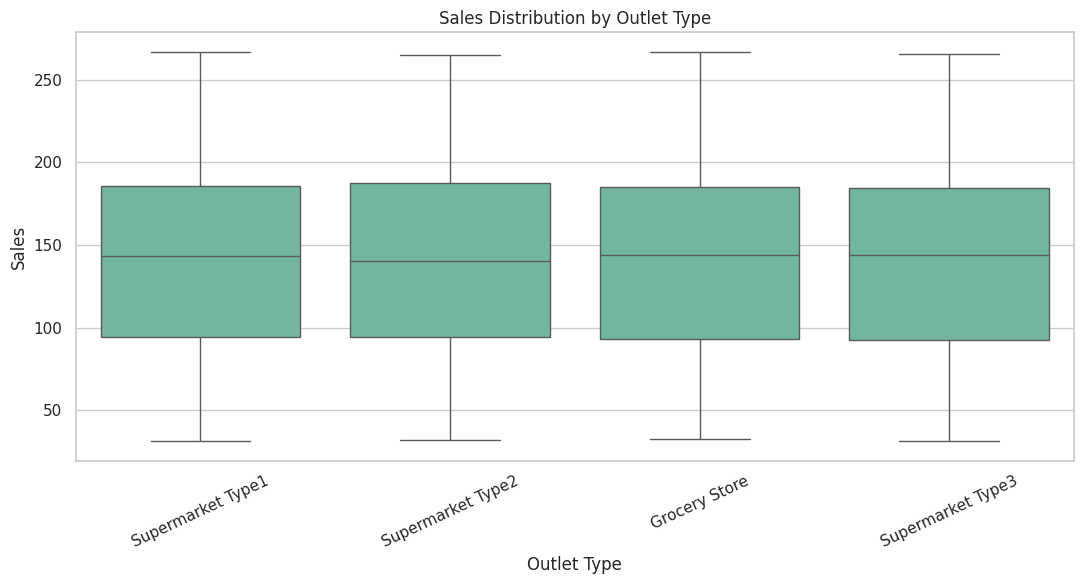

In [20]:
plt.figure(figsize=(11, 6))
sns.boxplot(data=df, x="Outlet Type", y="Sales")
plt.title("Sales Distribution by Outlet Type")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

**19. Correlation analysis**

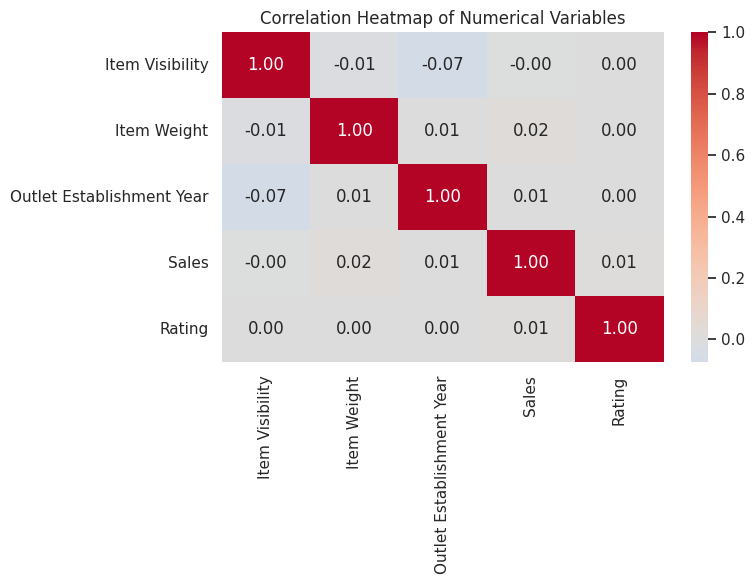

,Item Visibility,Item Weight,Outlet Establishment Year,Sales,Rating
Item Visibility,1.00,-0.01,-0.07,-0.00,0.00
Item Weight,-0.01,1.00,0.01,0.02,0.00
Outlet Establishment Year,-0.07,0.01,1.00,0.01,0.00
Sales,-0.00,0.02,0.01,1.00,0.01
Rating,0.00,0.00,0.00,0.01,1.00


In [21]:
numeric_cols = [
    "Item Visibility",
    "Item Weight",
    "Outlet Establishment Year",
    "Sales",
    "Rating"
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

display(correlation)

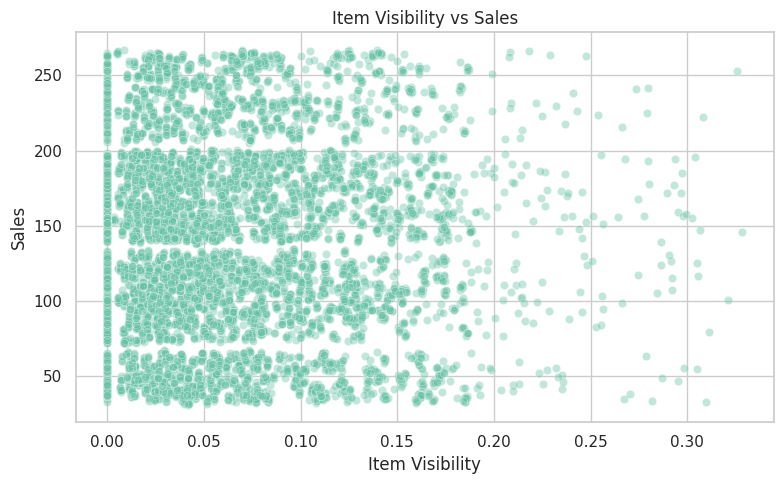

In [22]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Item Visibility", y="Sales", alpha=0.4)
plt.title("Item Visibility vs Sales")
plt.tight_layout()
plt.show()

**20. Additional business questions**

In [23]:
# Top five item types by total sales
top_5_item_types = df.groupby("Item Type")["Sales"].sum().nlargest(5)
print("Top 5 item types by sales:")
display(top_5_item_types)

# Top outlets by total sales
top_outlets = df.groupby("Outlet Identifier")["Sales"].sum().sort_values(ascending=False)
print("Outlet sales ranking:")
display(top_outlets)

# Sales and ratings by fat content
fat_content_summary = df.groupby("Item Fat Content").agg(
    Total_Sales=("Sales", "sum"),
    Average_Sales=("Sales", "mean"),
    Item_Records=("Sales", "count"),
    Average_Rating=("Rating", "mean")
).sort_values("Total_Sales", ascending=False)

print("Fat content performance:")
display(fat_content_summary)

Top 5 item types by sales:


,Sales
Item Type,
Fruits and Vegetables,"178,124.08"
Snack Foods,"175,433.92"
Household,"135,976.53"
Frozen Foods,"118,558.88"
Dairy,"101,276.46"


Outlet sales ranking:


,Sales
Outlet Identifier,
OUT035,"133,103.91"
OUT046,"132,113.37"
OUT013,"131,809.02"
OUT018,"131,477.77"
OUT045,"130,942.78"
OUT027,"130,714.67"
OUT049,"130,476.86"
OUT017,"129,103.96"
OUT010,"78,131.56"


Fat content performance:


,Total_Sales,Average_Sales,Item_Records,Average_Rating
Item Fat Content,,,,
Low Fat,"776,319.68",140.71,5517,3.97
Regular,"425,361.80",141.50,3006,3.97


**21. Automatically generate evidence-based findings**

In [24]:
best_item_type = item_sales.idxmax()
best_item_sales = item_sales.max()

best_outlet = df.groupby("Outlet Identifier")["Sales"].sum().idxmax()
best_outlet_sales = df.groupby("Outlet Identifier")["Sales"].sum().max()

best_location = location_sales.idxmax()
best_location_sales = location_sales.max()

best_outlet_size = size_sales.idxmax()
best_size_sales = size_sales.max()

best_fat_group = fat_sales.idxmax()
best_fat_sales = fat_sales.max()

print("BUSINESS FINDINGS")
print("-" * 55)
print(f"1. Highest-sales item type: {best_item_type} ({best_item_sales:,.2f})")
print(f"2. Highest-sales outlet: {best_outlet} ({best_outlet_sales:,.2f})")
print(f"3. Highest-sales location tier: {best_location} ({best_location_sales:,.2f})")
print(f"4. Highest-sales outlet size: {best_outlet_size} ({best_size_sales:,.2f})")
print(f"5. Highest-sales fat-content group: {best_fat_group} ({best_fat_sales:,.2f})")
print(f"6. Average rating across records: {average_rating:.2f} out of 5")

BUSINESS FINDINGS
-------------------------------------------------------
1. Highest-sales item type: Fruits and Vegetables (178,124.08)
2. Highest-sales outlet: OUT035 (133,103.91)
3. Highest-sales location tier: Tier 3 (472,133.03)
4. Highest-sales outlet size: Medium (507,895.73)
5. Highest-sales fat-content group: Low Fat (776,319.68)
6. Average rating across records: 3.97 out of 5


**22. Business recommendations**
Use the actual outputs above to write recommendations. Examples of recommendation areas (confirm them against your results before keeping them):

**1. Product planning:** Review the highest- and lowest-sales item types when planning assortment and promotions.

**2. Outlet strategy:** Compare outlet types and location tiers before deciding where to prioritize operational improvements.

**3. Inventory planning:** Use item-level sales contribution as one input to replenishment planning; this dataset does not include stock-on-hand or stockout data.

**4. Customer experience**
Investigate categories or outlets with comparatively lower ratings; ratings alone do not explain the reason.

**5. Data limitations:** Add transaction dates, order IDs, costs, inventory levels and geographic coordinates in a future dataset to support trend, profit, customer and map analysis.
Do not claim that a category is profitable or that a location is geographically best based only on sales.

**23.Final conclusion**

In [25]:
print(f"The dataset contains {len(df):,} item records and {df['Item Identifier'].nunique():,} distinct item identifiers.")
print(f"Total recorded sales are {df['Sales'].sum():,.2f}, with average sales of {df['Sales'].mean():,.2f} per record.")
print(f"The average item rating is {df['Rating'].mean():.2f} out of 5.")
print(f"The leading item type by sales is {best_item_type}.")
print(f"The leading outlet by sales is {best_outlet}.")
print("The analysis compares product, fat-content, outlet, outlet-size and location-tier performance using Python visualizations.")

The dataset contains 8,523 item records and 1,559 distinct item identifiers.
Total recorded sales are 1,201,681.48, with average sales of 140.99 per record.
The average item rating is 3.97 out of 5.
The leading item type by sales is Fruits and Vegetables.
The leading outlet by sales is OUT035.
The analysis compares product, fat-content, outlet, outlet-size and location-tier performance using Python visualizations.


**24.export cleaned data and analysis tables**

In [26]:
# Export cleaned dataset
df.to_csv("Blinkit_Cleaned_Data.csv", index=False)

# Export selected summary tables
kpi_summary.to_csv("Blinkit_KPI_Summary.csv", index=False)
item_summary.to_csv("Blinkit_Item_Type_Summary.csv")
outlet_summary.to_csv("Blinkit_Outlet_Type_Summary.csv")
location_sales.to_csv("Blinkit_Location_Summary.csv", header=["Total Sales"])

print("Files created successfully.")

Files created successfully.
